# Module 12 Assignment: Text Analytics and NLP
**CS 5045: Computation for the Data Sciences**

**Name:** Vaishnavi Madagiri

---

Complete each section below by filling in the blanks marked `__________` or writing code where indicated. Run all cells top to bottom and make sure there are no errors before submitting.

**Dataset:** `data.csv`: 260 product reviews. The file is in the same folder as this notebook.

**Libraries you may use:** `pandas`, `re` (standard library), `collections.Counter`, `matplotlib.pyplot`. Do NOT import NLTK, spaCy, or any other external NLP package.

**Also needed for Section 7:** the local C compiler you set up for Seminar 3.

In [1]:
import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt

# Provided constants: use these in Sections 3 and 5.

STOP_WORDS = {
    "the", "a", "an", "and", "is", "in", "it", "to", "for",
    "of", "my", "i", "at", "this", "very", "but", "after",
    "even", "are", "not", "do", "from", "be", "all", "have",
    "too", "was", "on", "up", "so", "one", "has", "me",
    "they", "get", "its", "that", "with", "what", "no"
}

POSITIVE_WORDS = {
    "great", "excellent", "amazing", "comfortable", "best", "perfect",
    "love", "awesome", "smooth", "accurate", "lightweight", "fantastic",
    "sturdy", "loud", "clear", "rich", "intuitive", "quickly", "grip"
}

NEGATIVE_WORDS = {
    "broke", "terrible", "worst", "disappointed", "cracked", "inaccurate",
    "flimsy", "weak", "waste", "leaks", "scratched", "confusing", "drains",
    "wobbles", "muddy", "awful", "horrible", "worthless", "smells"
}

## Section 1: Load and Inspect

In [2]:
# 1a. Load data.csv into a DataFrame named df.
df = pd.read_csv("data.csv")

# 1b. Print the shape of the DataFrame.
#     Expected output: (260, 5)
print("Shape:", df.shape)

# 1c. Print the first 3 entries in the review_text column.
#     Use .iloc or .head() to access the first 3 rows.
print("\nSample reviews:")
print(df["review_text"].head(3))

# 1d. Print the total number of documents (rows) in the corpus.
print("\nTotal documents in corpus:", len(df))

Shape: (260, 5)

Sample reviews:
0    Love the accuracy of this fitness tracker. Hea...
1    Excellent coffee maker that is very easy to us...
2    Poor accuracy for heart rate monitoring. Sleep...
Name: review_text, dtype: object

Total documents in corpus: 260


## Section 2: Tokenize and Clean

In [3]:
# 2a. Complete the tokenize function below.
#     It should:
#       (1) convert the text to lowercase
#       (2) remove punctuation using re.sub(r"[^a-z\s]", "", text)
#       (3) split the cleaned string into a list of words
#     Return the list of words.

def tokenize(text):
    """
    TRANSFORM: clean and tokenize a single review string.

    Parameters:
        text (str) -- raw review text

    Returns:
        list -- list of lowercase, punctuation-free word tokens
    """
    text = text.lower()          # step 1: lowercase
    text = re.sub(r"[^a-z\s]", "", text)   # step 2: remove punctuation
    return text.split()          # step 3: split into words


# 2b. Test your function on one string.
#     Expected: ['best', 'coffee', 'maker', 'ive', 'ever', 'owned']
sample = "Best coffee maker I've ever owned!"
print("Test tokenize:", tokenize(sample))

# 2c. Apply tokenize to the review_text column.
#     Store the result in a new column called 'tokens'.
df["tokens"] = df["review_text"].apply(tokenize)

# 2d. Print the tokens for the first review to confirm.
print("\nTokens for review 1:")
print(df["tokens"].iloc[0])

Test tokenize: ['best', 'coffee', 'maker', 'ive', 'ever', 'owned']

Tokens for review 1:
['love', 'the', 'accuracy', 'of', 'this', 'fitness', 'tracker', 'heart', 'rate', 'and', 'sleep', 'monitoring', 'are', 'excellent', 'app', 'is', 'very', 'easy', 'to', 'use']


## Section 3: Stop Word Filter

In [4]:
# 3a. Create a new column 'tokens_filtered' by removing stop words
#     from each review's token list.
#     Use .apply() with a lambda and a list comprehension:
#       keep word w if w is NOT in STOP_WORDS.

df["tokens_filtered"] = df["tokens"].apply(
    lambda words: [w for w in words if w not in STOP_WORDS]
)

# 3b. Print the before and after for the first review.
print("Before filtering:")
print(df["tokens"].iloc[0])
print("\nAfter filtering:")
print(df["tokens_filtered"].iloc[0])

# 3c. In one sentence (as a comment), explain why stop word removal matters.
# Answer: It removes common words so we can focus on important words.

Before filtering:
['love', 'the', 'accuracy', 'of', 'this', 'fitness', 'tracker', 'heart', 'rate', 'and', 'sleep', 'monitoring', 'are', 'excellent', 'app', 'is', 'very', 'easy', 'to', 'use']

After filtering:
['love', 'accuracy', 'fitness', 'tracker', 'heart', 'rate', 'sleep', 'monitoring', 'excellent', 'app', 'easy', 'use']


## Section 4: Word Frequency

In [5]:
# 4a. Flatten all filtered token lists into a single Python list called all_tokens.
#     Hint: create an empty list, then loop over df['tokens_filtered'] with .extend().
all_tokens = []
for token_list in df["tokens_filtered"]:
    all_tokens.extend(token_list)

# 4b. Use Counter to count how often each word appears.
#     Store the result in word_counts.
word_counts = Counter(all_tokens)

# 4c. Print the top 10 most common words.
top10 = word_counts.most_common(10)
print("Top 10 words after stop word removal:")
for word, count in top10:
    print(f"  {word:<20} {count}")

Top 10 words after stop word removal:
  excellent            125
  quality              112
  coffee               102
  recommend            77
  comfortable          71
  battery              63
  highly               62
  sound                61
  heart                60
  rate                 60


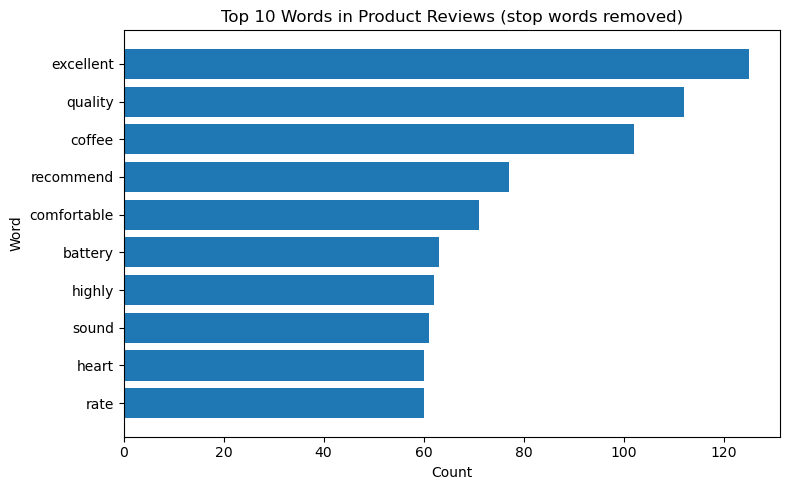

In [6]:
# 4d. Create a horizontal bar chart of the top 10 words.
#     Use matplotlib. Words go on the y-axis; counts on the x-axis.
#     Add a title and axis labels. Reverse the list so the highest bar is at the top.

words  = [w for w, c in top10]
counts = [c for w, c in top10]

fig, ax = plt.subplots(figsize=(8, 5))
# Fill in the bar chart code:
ax.barh(words[::-1], counts[::-1])

ax.set_title("Top 10 Words in Product Reviews (stop words removed)")
ax.set_xlabel("Count")
ax.set_ylabel("Word")
plt.tight_layout()
plt.show()

## Section 5: Sentiment

In [7]:
# 5a. Complete the classify_review function below.
#
#     Logic:
#       - Count how many tokens appear in POSITIVE_WORDS  (pos_score)
#       - Count how many tokens appear in NEGATIVE_WORDS  (neg_score)
#       - If pos_score > neg_score: return "positive"
#       - If neg_score > pos_score: return "negative"
#       - Otherwise:                return "neutral"
#
#     Hint for the count: sum(1 for w in tokens if w in POSITIVE_WORDS)
#     This adds 1 for each word in the token list that also appears in the word set.

def classify_review(tokens):
    """
    TRANSFORM: classify a token list as positive, negative, or neutral.

    Parameters:
        tokens (list) -- list of word tokens from a single review

    Returns:
        str -- "positive", "negative", or "neutral"
    """
    pos_score = sum(1 if w in POSITIVE_WORDS else 0 for w in tokens)
    neg_score = sum(1 if w in NEGATIVE_WORDS else 0 for w in tokens)
    if pos_score > neg_score:
        return "positive"
    elif neg_score > pos_score:
        return "negative"
    else:
        return "neutral"


# 5b. Apply classify_review to the 'tokens_filtered' column.
#     Store the result in a new column 'sentiment'.
df["sentiment"] = df["tokens_filtered"].apply(classify_review)

# 5c. Print the sentiment counts.
print("Sentiment distribution:")
print(df["sentiment"].value_counts())

Sentiment distribution:
sentiment
positive    172
negative     68
neutral      20
Name: count, dtype: int64


In [8]:
# 5d. Print the 5 most positive documents.
#     Add a 'pos_score' column by applying a lambda that computes pos_score
#     for each row's tokens_filtered list (same logic as classify_review).

df["pos_score"] = df["tokens_filtered"].apply(
    lambda tokens: sum(1 for w in tokens if w in POSITIVE_WORDS)
)

# Sort by pos_score descending and print top 5
top_positive = df.sort_values("pos_score", ascending=False).head(5)
print("Top 5 most positive reviews:")
print(top_positive[["product", "rating", "sentiment", "review_text"]].to_string(index=False))

# 5e. Print the 5 most negative documents.
#     Add a 'neg_score' column (same approach as 5d but for NEGATIVE_WORDS).
df["neg_score"] = df["tokens_filtered"].apply(
    lambda tokens: sum(1 for w in tokens if w in NEGATIVE_WORDS)
)

top_negative = df.sort_values("neg_score", ascending=False).head(5)
print("\nTop 5 most negative reviews:")
print(top_negative[["product", "rating", "sentiment", "review_text"]].to_string(index=False))

Top 5 most positive reviews:
            product  rating sentiment                                                                                                                 review_text
      Running Shoes       4  positive     Excellent shoes with great cushioning and support. Very comfortable and lightweight. Perfect for long distance running.
      Running Shoes       5  positive    Love these running shoes. They are very comfortable and provide excellent support. Lightweight and durable. Perfect fit.
Wireless Headphones       4  positive       Excellent product. Sound is clear and crisp with great bass response. The headphones are comfortable and lightweight.
Wireless Headphones       5  positive Love the rich sound quality of these headphones. Very comfortable and lightweight. Battery life is excellent for daily use.
      Running Shoes       4  positive           Love the lightweight design and excellent cushioning. These shoes provide great support and are very comfortable.

**5f.** In 2-3 sentences, describe one type of review that your `classify_review` function
would handle poorly, and explain why.

**Your answer:** A sarcastic review could be labeled wrong. The function only counts positive and negative words, so it does not understand sarcasm.

---
## Section 6: Code From Scratch

No blanks this time. You get the question only; write the full code yourself. This composes two things you have already done separately: filtering with a condition, and the tokenize + stop-word-filter + Counter pipeline from Sections 2-4.

**Question:** Split the reviews into two groups using the median `helpful_votes`: reviews above the median, and reviews at or below it. For each group, flatten `tokens_filtered` and find the top 5 words. Which group's top 5 includes a negative word that the other group's does not? What does this suggest about which reviews other customers mark as "helpful"?

In [9]:
# Write your own code below. No starter code or blanks are provided for this section.
#
# Compute the median of helpful_votes.
# Split df into two groups: above the median, and at-or-below the median.
# For each group, flatten tokens_filtered and print the top 5 words with Counter.

median = df["helpful_votes"].median()
above = df[df["helpful_votes"] > median]
below = df[df["helpful_votes"] <= median]

above_words = []
for words in above["tokens_filtered"]:
    above_words.extend(words)

below_words = []
for words in below["tokens_filtered"]:
    below_words.extend(words)

print("Median:", median)
print("Above median:", Counter(above_words).most_common(5))
print("At or below median:", Counter(below_words).most_common(5))

Median: 21.0
Above median: [('quality', 65), ('excellent', 56), ('coffee', 53), ('recommend', 45), ('poor', 40)]
At or below median: [('excellent', 69), ('coffee', 49), ('quality', 47), ('comfortable', 45), ('tracker', 34)]


**Reflection:** In one sentence, what does the difference between the two lists tell you about the kind of review other customers find most useful?

**Your answer:** The more helpful reviews include the negative word "poor," so customers may find reviews about problems useful.

---
## Section 7: Back to C

A short callback to the C compiler exercise from Seminar 3, now inside this notebook. The
program below is supposed to count how many words in a short list match a target word,
ignoring case: "Good" should count as a match for "good". It has a bug: it is undercounting.

This is the exact same mistake Section 2 of this assignment exists to prevent: comparing
text without normalizing case first.

**Run the cell below once as-is first**, so you can see the buggy output before you fix anything.

In [10]:
%%writefile word_match.c
#include <stdio.h>
#include <string.h>
#include <ctype.h>

int words_match(const char *a, const char *b) {
    if (strlen(a) != strlen(b)) {
        return 0;
    }
    for (int i = 0; a[i] != '\0'; i++) {
        if (a[i] != b[i]) {
            return 0;
        }
    }
    return 1;
}

int main() {
    const char *words[] = {"This", "coffee", "maker", "is", "good", "very", "good", "Good", "quality"};
    int n = 9;
    const char *target = "good";
    int count = 0;

    for (int i = 0; i < n; i++) {
        if (words_match(words[i], target)) {
            count++;
        }
    }

    printf("Occurrences of \"%s\" (intended case-insensitive): %d\n", target, count);
    return 0;
}

Writing word_match.c


In [11]:
# Compile the C source into an executable named "word_match".
# This is a shell command run from inside the notebook, not Python code.
!gcc word_match.c -o word_match

In [13]:
# Now call the compiled C program from Python using subprocess, and capture its output.
# This is the same idea as df["tokens"].apply(tokenize): a function does the work,
# and the result comes back to you to use.

import subprocess

result = subprocess.run(["./word_match"], capture_output=True, text=True)
print(result.stdout)

# Buggy output (before you fix anything): "Occurrences of "good" (intended case-insensitive): 2"
# This is wrong. "Good" (capital G) should count too.

Occurrences of "good" (intended case-insensitive): 2



**Now fix it.** Scroll back up to the `%%writefile word_match.c` cell. The bug is in
`words_match`: it compares raw characters, so `'G'` and `'g'` are never equal. Fix the
comparison so it ignores case (the `tolower()` function from `<ctype.h>` converts one
character to lowercase; it takes one character and returns the lowercase version). Re-run
that cell, then re-run the compile cell, then re-run the `subprocess` cell. Confirm you
now get:

```
Occurrences of "good" (intended case-insensitive): 3
```

**Question 7a.** What was the bug, in one sentence? Where in Section 2's `tokenize`
function does Python do the equivalent fix, and what would happen to your word frequency
table in Section 4 if `tokenize` skipped that step?

**Question 7b.** What does the compile step (`gcc word_match.c -o word_match`) do that
never happens when you run a `.py` file?

*Your answer to 7a here.* The bug was that C treated uppercase and lowercase letters as different. Python fixes this with text.lower() in Section 2 without it, words like "Good" and "good" would be counted separately.

*Your answer to 7b here.* The compile step turns the C code into an executable program before running it, while Python runs without a separate compile command.